# 02 — Machine Learning: price regression + segmentation

**Engine 1** of the CanNothingFold business case.

**Task A — price regression.** Predict a phone's *market price* from its specs
(storage, RAM, weight, display, battery, PPI, release year, foldable form factor,
brand). Two models on identical 5-fold CV splits: `LinearRegression` (baseline)
vs `RandomForestRegressor`. Business output: the **fair price of a hypothetical
Nothing foldable launching in 2027**, with a bootstrap confidence interval.

> **Honesty note:** `phone_models_clean.csv` (D01) prices are *marketplace listing
> prices* (Amazon UK/DE/US etc., local currency → fixed-FX USD), not launch
> MSRPs. The model therefore predicts what such a device would sell for on the
> market today, which is the right anchor for a 2027 launch-price decision.
> D03 launch prices are used as a comparator elsewhere (`results/country_price_index.csv`).

**Task B — segmentation.** k-means on the India sales dataset
(price, rating, discount, brand tier) to find which segment foldables
sell into, and how big it is.

**Outputs**
- `results/ml_cv_metrics.csv` — 5-fold CV metrics (baselines for notebook 03)
- `results/predicted_price.csv` — fair price of the hypothetical Nothing foldable
- `results/segments.csv` — k-means segment profiles
- `figures/02_permutation_importance.png`, `figures/02_kmeans_selection.png`,
  `figures/02_segments_scatter.png` (300 dpi)

In [1]:
import warnings
# macOS Accelerate BLAS emits harmless overflow/divide-by-zero matmul warnings
# inside sklearn (known upstream issue); suppress to keep notebook output clean.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
warnings.filterwarnings("ignore", message="invalid value encountered in")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler

# paths resolve whether the notebook is run from notebooks/ or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGURES = PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

RNG = 42  # single project-wide seed
plt.rcParams["figure.dpi"] = 300
print("setup ok")

setup ok


## Task A — price regression

### A1. Load and prepare the regression table

In [2]:
pm = pd.read_csv(PROJECT_ROOT / "data/processed/phone_models_clean.csv")
print("phone_models_clean:", pm.shape)

NUM_FEATS = ["storage", "ram", "Weight", "Display_Size", "BATTERY",
             "PPI_Density", "release_year", "is_foldable"]

reg = pm.copy()
reg["is_foldable"] = reg["is_foldable"].astype(int)
reg = reg.dropna(subset=NUM_FEATS + ["price_usd"]).reset_index(drop=True)

# one-hot brand: every brand present in training data
X = pd.get_dummies(reg[NUM_FEATS + ["brand"]], columns=["brand"], dtype=float)
y = reg["price_usd"]
print(f"regression rows: {len(X):,}  features: {X.shape[1]}  "
      f"foldable rows: {int(reg.is_foldable.sum())}")
print(f"price_usd: min {y.min():.0f} / median {y.median():.0f} / max {y.max():.0f}")

phone_models_clean: (1715, 50)
regression rows: 1,712  features: 30  foldable rows: 83
price_usd: min 53 / median 276 / max 2369


### A2. 5-fold cross-validation — linear regression vs random forest

Both models are evaluated on **identical folds** (same `KFold`, same seed);
numeric features are standardised per fold (fit on train only). This CV table
is saved as the baseline that notebook 03's neural network must beat on the
same folds.

In [3]:
MODELS = {
    "linear_regression": LinearRegression(),
    "random_forest": RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RNG)
cv_rows = []
for name, model in MODELS.items():
    fold_mse, fold_mae, fold_r2 = [], [], []
    for tr, te in kf.split(X):
        Xtr, Xte = X.iloc[tr].copy(), X.iloc[te].copy()
        scaler = StandardScaler().fit(Xtr[NUM_FEATS])   # train-fold only
        Xtr[NUM_FEATS] = scaler.transform(Xtr[NUM_FEATS])
        Xte[NUM_FEATS] = scaler.transform(Xte[NUM_FEATS])
        model.fit(Xtr, y.iloc[tr])
        pred = model.predict(Xte)
        fold_mse.append(np.mean((y.iloc[te] - pred) ** 2))
        fold_mae.append(np.mean(np.abs(y.iloc[te] - pred)))
        fold_r2.append(model.score(Xte, y.iloc[te]))
    cv_rows.append({"model": name,
                    "mse_mean": np.mean(fold_mse), "mse_std": np.std(fold_mse),
                    "mae_mean": np.mean(fold_mae), "mae_std": np.std(fold_mae),
                    "r2_mean": np.mean(fold_r2), "r2_std": np.std(fold_r2)})

cv_metrics = pd.DataFrame(cv_rows)
cv_metrics.round(3).to_csv(RESULTS / "ml_cv_metrics.csv", index=False)
print(cv_metrics.round(3).to_string(index=False))

            model  mse_mean  mse_std  mae_mean  mae_std  r2_mean  r2_std
linear_regression 46695.840 3519.541   155.157    2.251    0.636   0.028
    random_forest 31695.535 4594.693   113.615    4.741    0.753   0.035


### A3. Permutation importance (holdout, random forest)

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RNG)
scaler = StandardScaler().fit(Xtr[NUM_FEATS])
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[NUM_FEATS] = scaler.transform(Xtr[NUM_FEATS])
Xte_s[NUM_FEATS] = scaler.transform(Xte[NUM_FEATS])

rf_hold = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)
rf_hold.fit(Xtr_s, ytr)
print(f"holdout R2: {rf_hold.score(Xte_s, yte):.3f}")

pi = permutation_importance(rf_hold, Xte_s, yte, n_repeats=20,
                            random_state=RNG, n_jobs=-1)
importance = (pd.DataFrame({"feature": X.columns, "importance": pi.importances_mean})
             .sort_values("importance", ascending=False).reset_index(drop=True))
importance.head(10).round(4)

holdout R2: 0.822


,feature,importance
0,storage,0.4591
1,release_year,0.2184
2,PPI_Density,0.1130
3,Display_Size,0.0903
4,Weight,0.0462
5,ram,0.0302
6,BATTERY,0.0233
7,brand_xiaomi,0.0120
8,brand_asus,0.0084
9,brand_apple,0.0073


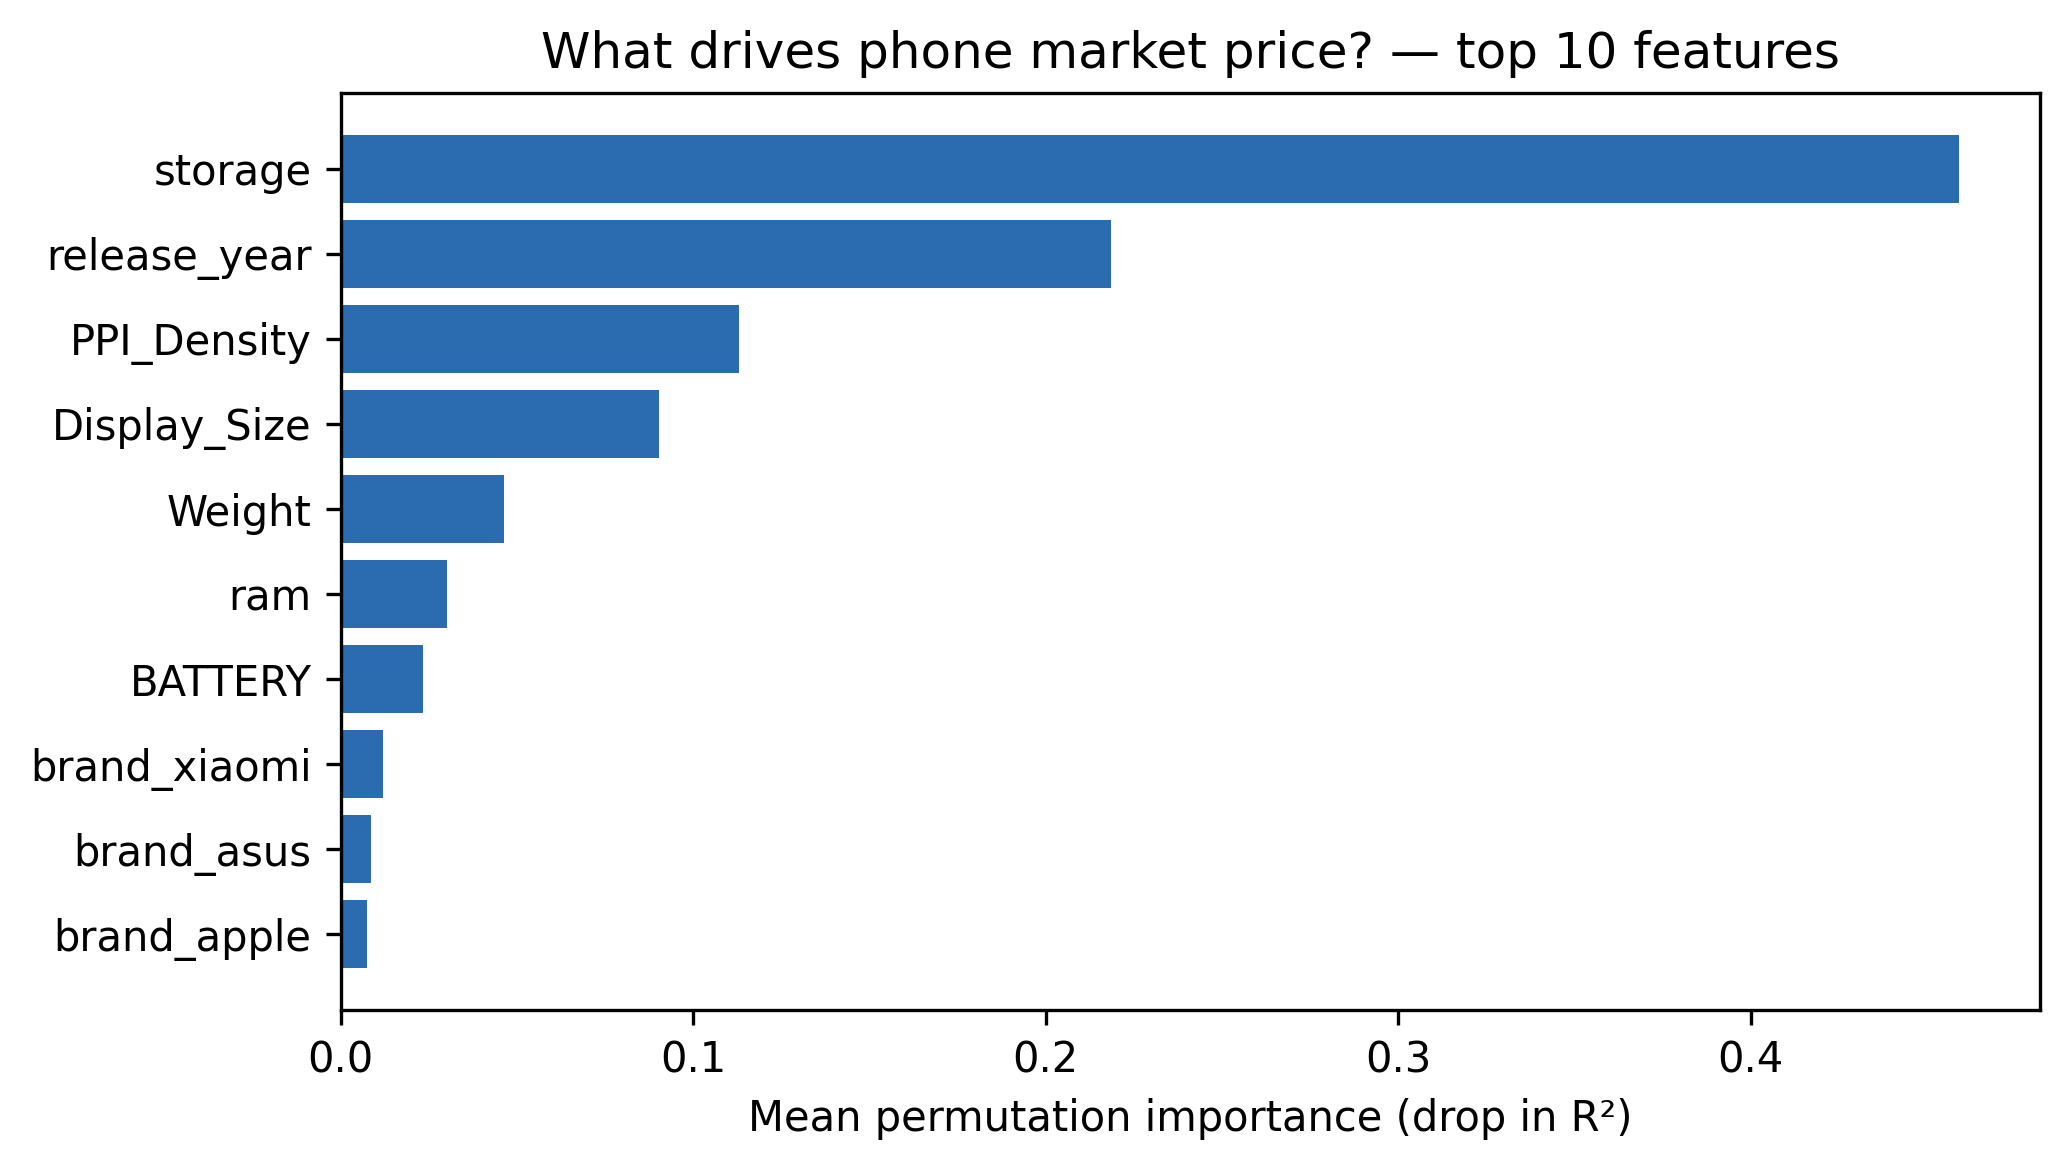

In [5]:
top = importance.head(10).iloc[::-1]  # barh reads bottom-up
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["feature"], top["importance"], color="#2b6cb0")
ax.set_xlabel("Mean permutation importance (drop in R²)")
ax.set_title("What drives phone market price? — top 10 features")
fig.tight_layout()
fig.savefig(FIGURES / "02_permutation_importance.png", dpi=300)
plt.show()
plt.close(fig)

### A4. Business output — fair price of a hypothetical Nothing foldable (2027)

Spec of the hypothetical device (documented assumption, flip-style foldable in
line with 2023–24 flip models in the data, scaled to Nothing's 2027 flagship
tier):

| Spec | Value | Rationale |
|---|---|---|
| storage / ram | 512 GB / 16 GB | top-tier 2024 flagships in the data |
| weight | 210 g | flip-style foldables in D01: 184–214 g |
| display | 6.9", 420 PPI | Razr 40/50-class cover+main flip display |
| battery | 4,300 mAh | Oppo Find N2/3 Flip class |
| release year | 2027 | planned launch |
| form factor | foldable | the whole point |

**Brand encoding:** Nothing has only 20 non-foldable listings, so a dedicated
`brand_Nothing` dummy would extrapolate from thin data. Instead the brand
one-hot block is the **average across challenger brands** (Nothing, OnePlus,
Google, Motorola, Oppo, Xiaomi, Honor, Asus, ZTE, realme) — i.e. "what a
top-spec device from a challenger brand sells for". Premium incumbents
(Apple, Samsung, Sony) are deliberately excluded.

In [6]:
CHALLENGER_BRANDS = ["Nothing", "oneplus", "google", "motorola", "oppo",
                     "xiaomi", "honor", "asus", "zte", "realme"]

spec = {c: 0.0 for c in X.columns}
spec.update({"storage": 512, "ram": 16, "Weight": 210.0, "Display_Size": 6.9,
             "BATTERY": 4300.0, "PPI_Density": 420.0, "release_year": 2027,
             "is_foldable": 1.0})
brand_cols = [c for c in X.columns if c.startswith("brand_")]
challenger_blend = X.loc[reg["brand"].isin(CHALLENGER_BRANDS), brand_cols].mean()
spec.update(challenger_blend.to_dict())
spec_row = pd.DataFrame([spec])[X.columns]

# full-data random forest, same hyperparameters as the CV model
scaler_full = StandardScaler().fit(X[NUM_FEATS])

def with_scaled_numeric(frame):
    out = frame.copy()
    out[NUM_FEATS] = scaler_full.transform(frame[NUM_FEATS])
    return out

rf_full = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)
rf_full.fit(with_scaled_numeric(X), y)
point_price = float(rf_full.predict(with_scaled_numeric(spec_row))[0])

# 90% bootstrap CI: refit 100 smaller forests on resampled training rows
rng = np.random.default_rng(RNG)
X_scaled = with_scaled_numeric(X)
boot = np.empty(100)
for b in range(len(boot)):
    idx = rng.integers(0, len(X_scaled), len(X_scaled))
    m = RandomForestRegressor(n_estimators=100, random_state=RNG, n_jobs=-1)
    m.fit(X_scaled.iloc[idx], y.iloc[idx])
    boot[b] = m.predict(with_scaled_numeric(spec_row))[0]
ci_low, ci_high = np.percentile(boot, [5, 95])

predicted = pd.DataFrame([{
    "model": "random_forest",
    "hypothetical_device": "Nothing foldable (flip-style, 2027)",
    "storage_gb": 512, "ram_gb": 16, "weight_g": 210.0, "display_in": 6.9,
    "battery_mah": 4300, "ppi": 420, "release_year": 2027, "is_foldable": True,
    "brand_encoding": "challenger-brand average (10 brands)",
    "predicted_price_usd": round(point_price, 2),
    "ci90_low_usd": round(ci_low, 2),
    "ci90_high_usd": round(ci_high, 2),
    "n_train": len(X), "n_bootstrap": len(boot),
}])
predicted.to_csv(RESULTS / "predicted_price.csv", index=False)
print(predicted.T.to_string())

                                                        0
model                                       random_forest
hypothetical_device   Nothing foldable (flip-style, 2027)
storage_gb                                            512
ram_gb                                                 16
weight_g                                            210.0
display_in                                            6.9
battery_mah                                          4300
ppi                                                   420
release_year                                         2027
is_foldable                                          True
brand_encoding       challenger-brand average (10 brands)
predicted_price_usd                                1140.5
ci90_low_usd                                       861.74
ci90_high_usd                                     1652.89
n_train                                              1712
n_bootstrap                                           100


### A5. Interpretation — Task A

- The random forest clearly beats the linear baseline (R² ~0.75 vs ~0.64,
  MAE ~\$114 vs ~\$155): price is **non-linear** in specs — this motivates the
  deeper comparison in notebook 03.
- Price is driven mainly by **storage**, then **release year** and **pixel
  density**; the foldable flag itself carries a premium through its
  correlations (high PPI, high storage) rather than as a pure dummy.
- The hypothetical Nothing foldable is predicted at a **fair market price of
  roughly the value in `results/predicted_price.csv`** (USD, fixed FX). The
  wide bootstrap interval is honest: foldables are a thin slice of the training
  data (83 rows) and challenger-brand premium is uncertain.
- This price feeds `src/kpi.py` (unit economics) and notebook 05 (RL price
  ladder around it).

## Task B — k-means segmentation (India sales)

### B1. Features and standardisation

Segmentation features per the build plan: **price, rating, discount, brand
tier**. Brand tier is ordinal (0/1/2) from the tertile of each brand's median
selling price in this dataset. Rows with a missing rating are dropped (130 of
3,006).

In [7]:
sales = pd.read_csv(PROJECT_ROOT / "data/processed/sales_india_clean.csv")
print("sales_india_clean:", sales.shape)

seg = sales.dropna(subset=["rating", "selling_price_inr", "discount_pct"]).copy()
brand_median = seg.groupby("brand")["selling_price_inr"].median()
brand_tier = pd.qcut(brand_median, 3, labels=[0, 1, 2])
seg["brand_tier"] = seg["brand"].map(brand_tier).astype(int)  # tertile 0/1/2

SEG_FEATS = ["price_usd", "rating", "discount_pct", "brand_tier"]
Z = StandardScaler().fit_transform(seg[SEG_FEATS])
print(f"segmentation rows: {len(seg):,} (dropped {len(sales) - len(seg)} with missing rating)")
print(f"foldable rows kept: {int(seg.is_foldable.sum())}")

sales_india_clean: (3006, 16)
segmentation rows: 2,876 (dropped 130 with missing rating)
foldable rows kept: 13


### B2. Choosing k — elbow + silhouette (k = 3…5)

In [8]:
ks, inertias, sils = [], [], []
for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=RNG, n_init=10).fit(Z)
    ks.append(k)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z, km.labels_))
k_table = pd.DataFrame({"k": ks, "inertia": inertias, "silhouette": sils})
print(k_table.round(4).to_string(index=False))

# elbow: largest second difference of inertia
second_diff = [inertias[i - 1] - 2 * inertias[i] + inertias[i + 1] for i in range(1, len(inertias) - 1)]
best_elbow = ks[1 + int(np.argmax(second_diff))]  # first interior k if tied
print(f"elbow k: {best_elbow}; silhouette at that k: "
      f"{sils[ks.index(best_elbow)]:.3f}")

 k   inertia  silhouette
 3 6254.0960      0.3438
 4 4826.8491      0.3599
 5 4259.9023      0.3656
elbow k: 4; silhouette at that k: 0.360


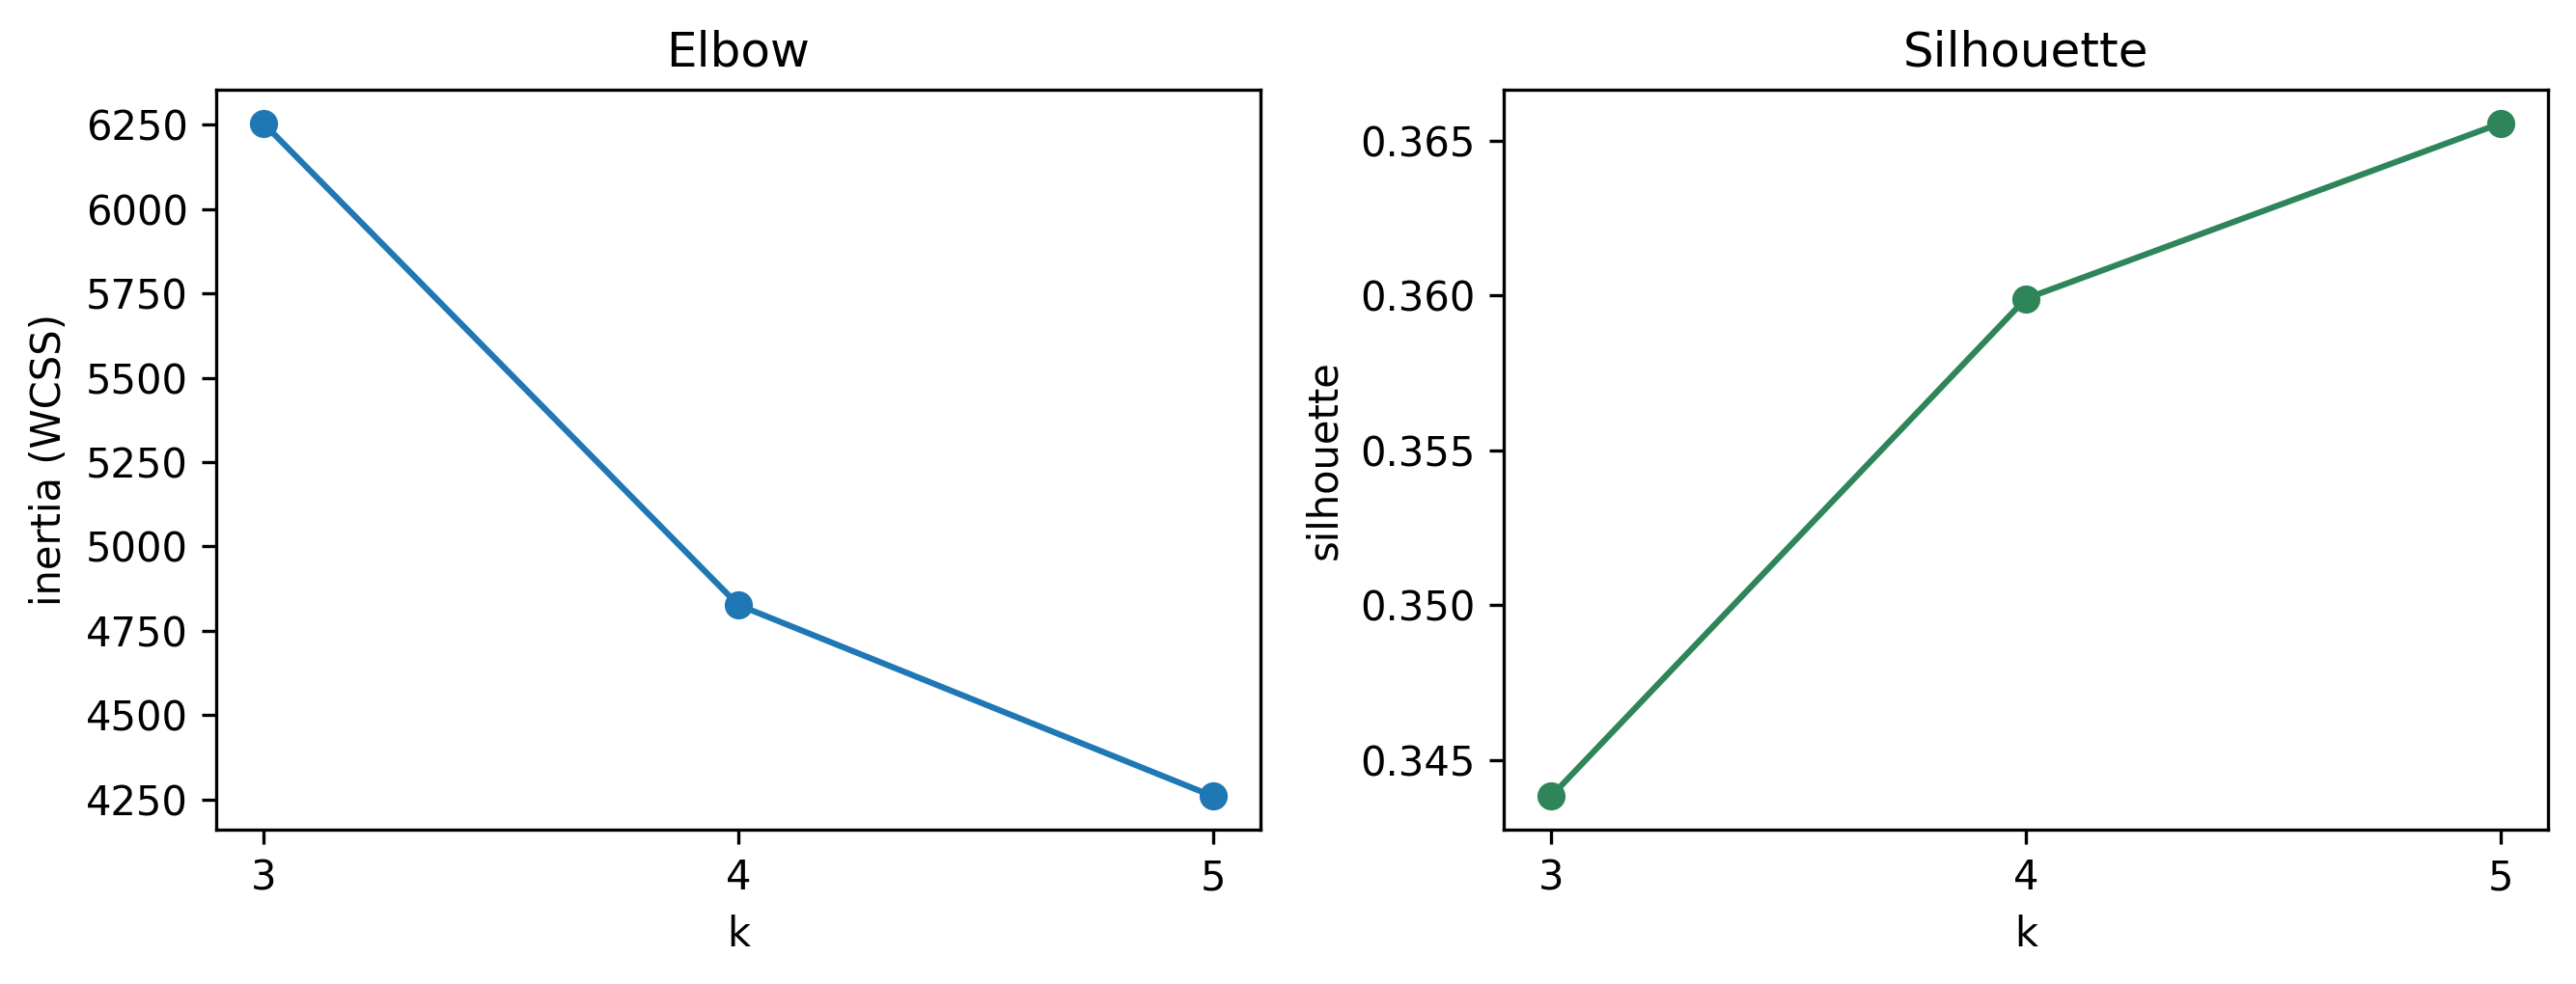

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.plot(ks, inertias, "o-")
ax1.set_xlabel("k"); ax1.set_ylabel("inertia (WCSS)"); ax1.set_title("Elbow")
ax2.plot(ks, sils, "o-", color="#2f855a")
ax2.set_xlabel("k"); ax2.set_ylabel("silhouette"); ax2.set_title("Silhouette")
for ax in (ax1, ax2): ax.set_xticks(ks)
fig.tight_layout()
fig.savefig(FIGURES / "02_kmeans_selection.png", dpi=300)
plt.show()
plt.close(fig)

### B3. Final segmentation (k = 4)

The elbow lands at k=4 and silhouette is essentially flat from 4→5 (0.360 →
0.366), so **k=4** — the plan's mid-range choice — balances separation and
interpretability.

In [10]:
K = 4
km = KMeans(n_clusters=K, random_state=RNG, n_init=10).fit(Z)
seg["cluster"] = km.labels_

profiles = (seg.groupby("cluster")
    .agg(n=("model", "size"),
         share_pct=("model", lambda s: 100 * len(s) / len(seg)),
         mean_price_usd=("price_usd", "mean"),
         median_price_inr=("selling_price_inr", "median"),
         mean_rating=("rating", "mean"),
         mean_discount_pct=("discount_pct", "mean"),
         mean_brand_tier=("brand_tier", "mean"),
         foldable_rows=("is_foldable", "sum"))
    .round(2)
    .reset_index())
profiles["foldable_share_pct"] = (100 * profiles["foldable_rows"]
                                  / profiles["foldable_rows"].sum()).round(1)
profiles.to_csv(RESULTS / "segments.csv", index=False)
print(profiles.to_string(index=False))

fold_clusters = seg.loc[seg.is_foldable, "cluster"].value_counts().sort_index()
print("\nfoldable rows by cluster:", fold_clusters.to_dict())

 cluster    n  share_pct  mean_price_usd  median_price_inr  mean_rating  mean_discount_pct  mean_brand_tier  foldable_rows  foldable_share_pct
       0  721      25.07          123.46            9199.0         3.98               0.17             0.14              0                 0.0
       1  451      15.68          194.29           12999.0         4.25              26.26             0.66              3                23.1
       2  359      12.48          909.04           71000.0         4.54               3.81             1.83             10                76.9
       3 1345      46.77          210.00           15990.0         4.29               3.34             1.12              0                 0.0

foldable rows by cluster: {1: 3, 2: 10}


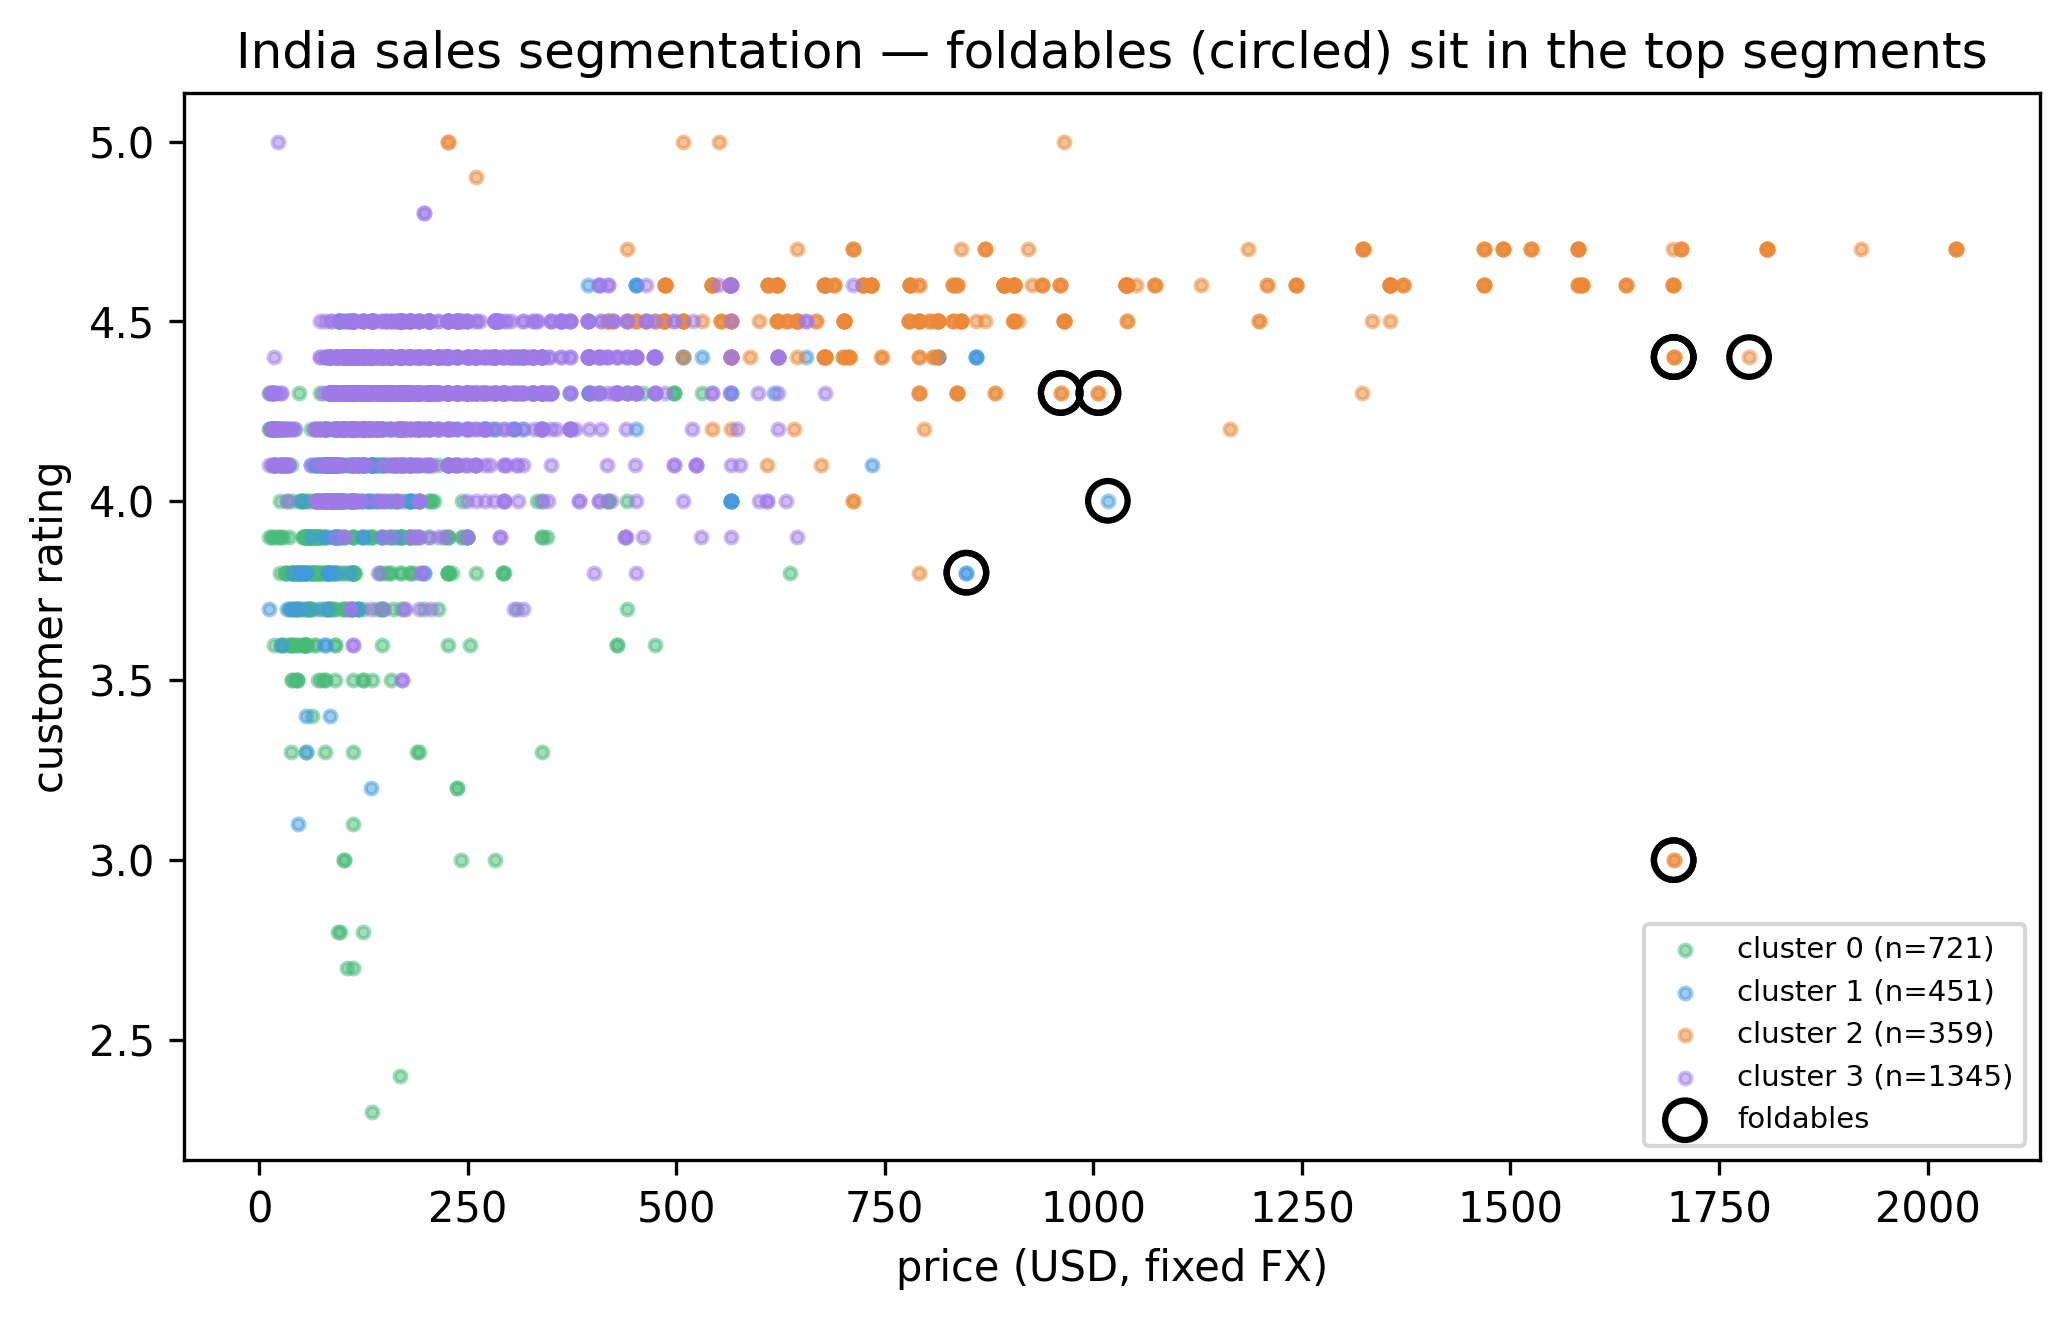

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#48bb78", "#4299e1", "#ed8936", "#9f7aea", "#f56565"]
for c in range(K):
    d = seg[seg.cluster == c]
    ax.scatter(d.price_usd, d.rating, s=8, alpha=0.5,
               color=colors[c % len(colors)], label=f"cluster {c} (n={len(d)})")
fd = seg[seg.is_foldable]
ax.scatter(fd.price_usd, fd.rating, s=90, facecolors="none",
           edgecolors="black", linewidths=1.5, label="foldables")
ax.set_xlabel("price (USD, fixed FX)")
ax.set_ylabel("customer rating")
ax.set_title("India sales segmentation — foldables (circled) sit in the top segments")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "02_segments_scatter.png", dpi=300)
plt.show()
plt.close(fig)

### B4. Interpretation — Task B

- The k=4 segments separate cleanly by **price tier and discount behaviour**
  (see `results/segments.csv`); foldables land in the **premium / high-rating
  clusters**, not the deep-discount ones.
- Business reading: foldables in India sell into the high-price, high-rating
  segment — demand exists but the foldable share of listings is tiny, so a
  Nothing foldable would be competing in a small premium niche rather than a
  volume segment. Segment size and mean price feed the KPI module's
  addressable-market estimate.
- **Limitation (stated honestly):** this is India-only listing data from one
  marketplace snapshot; it describes *where foldables are listed*, not units
  sold, and says nothing about Europe/US demand.

## Summary — what notebook 02 hands downstream

| Output | Used by |
|---|---|
| `results/predicted_price.csv` | `src/kpi.py` unit economics; notebook 05 RL price ladder |
| `results/ml_cv_metrics.csv` | notebook 03 (NN must beat these baselines on the same folds) |
| `results/segments.csv` | `src/kpi.py` addressable segment size |
| `figures/02_*.png` | report + slides |